In [23]:
# discretize state space into SOFA and AL bins
import numpy as np
import pandas as pd
import math  
import scipy.io

import matplotlib.pyplot as plt

In [24]:
Sepsis_data = pd.read_csv("../data/discretised_input_data.csv")
print(len(Sepsis_data))
# take patients 
sofa_bins = 25 # 0 - 24 

lactate_bins = 20 # choose 20 first 

278682


6.315499386397399


<ipython-input-25-5dbaf1c8d314>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sofa_df['binned'] = pd.cut(sofa_df, bins=sofa_bin)


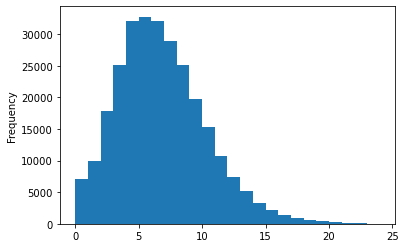

In [25]:
sofa_df = Sepsis_data['SOFA']
mean = sofa_df.mean()
print(mean)
sofa_bin = [i for i in range(25)]
#bin_float_range = [i for i in np.arange(0, 30, 0.5)]
sofa_df.plot(kind='hist', bins = sofa_bin)
sofa_df['binned'] = pd.cut(sofa_df, bins=sofa_bin)

In [26]:
Sepsis_data.columns

Index(['bloc', 'icustayid', 'charttime', 'gender', 'age', 'elixhauser',
       're_admission', 'died_in_hosp', 'died_within_48h_of_out_time',
       'mortality_90d', 'delay_end_of_record_and_discharge_or_death',
       'Weight_kg', 'GCS', 'HR', 'SysBP', 'MeanBP', 'DiaBP', 'RR', 'SpO2',
       'Temp_C', 'FiO2_1', 'Potassium', 'Sodium', 'Chloride', 'Glucose', 'BUN',
       'Creatinine', 'Magnesium', 'Calcium', 'Ionised_Ca', 'CO2_mEqL', 'SGOT',
       'SGPT', 'Total_bili', 'Albumin', 'Hb', 'WBC_count', 'Platelets_count',
       'PTT', 'PT', 'INR', 'Arterial_pH', 'paO2', 'paCO2', 'Arterial_BE',
       'Arterial_lactate', 'HCO3', 'mechvent', 'Shock_Index', 'PaO2_FiO2',
       'median_dose_vaso', 'max_dose_vaso', 'input_total', 'input_4hourly',
       'output_total', 'output_4hourly', 'cumulated_balance', 'SOFA', 'SIRS',
       'vaso_input', 'iv_input'],
      dtype='object')

2.040800541705534


<ipython-input-27-704de2fb9cce>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lactate_df['binned'] = pd.cut(lactate_df, bins=lactate_bin)


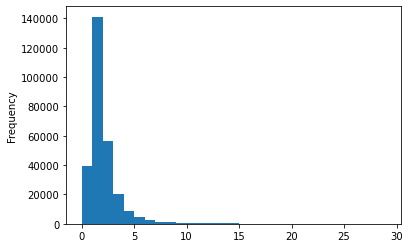

In [27]:
lactate_df = Sepsis_data['Arterial_lactate']
mean = lactate_df.mean()
print(mean)
lactate_bin = [i for i in range(30)]
#bin_float_range = [i for i in np.arange(0, 30, 0.5)]
lactate_df.plot(kind='hist', bins = lactate_bin)
lactate_df['binned'] = pd.cut(lactate_df, bins=lactate_bin)




In [28]:
lactate_df['binned']

0         (0, 1]
1         (1, 2]
2         (0, 1]
3         (0, 1]
4         (0, 1]
           ...  
278677    (2, 3]
278678    (0, 1]
278679    (1, 2]
278680    (1, 2]
278681    (1, 2]
Name: Arterial_lactate, Length: 278682, dtype: category
Categories (29, interval[int64]): [(0, 1] < (1, 2] < (2, 3] < (3, 4] ... (25, 26] < (26, 27] < (27, 28] < (28, 29]]

In [29]:
lactate_df['binned'].value_counts()

(1, 2]      134359
(0, 1]       54035
(2, 3]       50882
(3, 4]       19291
(4, 5]        7869
(5, 6]        4373
(6, 7]        2508
(7, 8]        1408
(8, 9]        1025
(9, 10]        745
(10, 11]       497
(11, 12]       389
(12, 13]       348
(13, 14]       258
(14, 15]       215
(15, 16]       133
(16, 17]        63
(17, 18]        49
(19, 20]        49
(18, 19]        46
(20, 21]        25
(23, 24]        23
(21, 22]        21
(25, 26]        21
(24, 25]        17
(22, 23]        10
(26, 27]         1
(27, 28]         1
(28, 29]         1
Name: Arterial_lactate, dtype: int64

In [30]:
# bin the 2 features accordingly -> 750 state MDP 
tupleToNumericStates = {}
numericStatesToTuple = {}
count = 0
for i in range(sofa_bins):
    for j in range(len(lactate_bin)):
        tupleToNumericStates[(i,j)] = count
        numericStatesToTuple[count] = (i,j)
        count += 1


In [31]:
# convert sepsis data to states
tupleToNumericStates[(5,10)]
numericStatesToTuple[749]

(24, 29)

In [32]:
# convert continuous variables to discrete states. Retain icu stay id, discretize actions. 
# add to the current sepsis data
states = []
for i in range(len(Sepsis_data)):
    row = Sepsis_data.iloc[i]
    sofa_score = row['SOFA']
    al_score = math.floor(row['Arterial_lactate'])
    state = tupleToNumericStates[(sofa_score, al_score)]
    states.append(state)
    
Sepsis_data['discrete_states'] = states

In [33]:
Sepsis_data['discrete_states'].value_counts() # only 519 / 750 states visited

151    17005
121    16674
181    16646
211    14956
91     13058
       ...  
141        1
652        1
140        1
651        1
630        1
Name: discrete_states, Length: 519, dtype: int64

In [34]:
# build transition probability matrix

# build actions
actions = {}
count = 0
for i in range(5):
    for j in range(5):
        actions[(i,j)] = count
        count += 1

        
sepsis_actions=[]
for i in range(len(Sepsis_data)):
    row = Sepsis_data.iloc[i]
    iv_input = row['iv_input']
    vaso_input = row['vaso_input']
    action = actions[(iv_input, vaso_input)]
    sepsis_actions.append(action)

Sepsis_data['actions'] = sepsis_actions
        

In [35]:
# build transition matrix
T = np.zeros((750, 25, 750))

for i in range(len(Sepsis_data) - 1):
    icu_id = Sepsis_data.iloc[i]['icustayid']
    icu_id_next = Sepsis_data.iloc[i+1]['icustayid']
    
    if (icu_id == icu_id_next):
        curr_state = int(Sepsis_data.iloc[i]['discrete_states'])
        next_state = int(Sepsis_data.iloc[i+1]['discrete_states'])
        curr_action = int(Sepsis_data.iloc[i]['actions'])

        T[curr_state][curr_action][next_state] += 1


# calculate probability density estimation
for i in range(750):
    for j in range(25):
        temp_sum = np.sum(T[i][j][:])
        T[i][j][:] = T[i][j][:] / temp_sum

<ipython-input-35-db147776e436>:20: RuntimeWarning: invalid value encountered in true_divide
  T[i][j][:] = T[i][j][:] / temp_sum


In [36]:
T[np.isnan(T)] = 0

In [37]:
# feature matrix. 6 features for SOFA and arterial lactate. SOFA 1 for increase, 1 for maintain, 1 for decrease then AL
# Define as S,A,S' again from data

F = np.zeros((750, 25, 750, 6))
for i in range(len(Sepsis_data) - 1):
    icu_id = Sepsis_data.iloc[i]['icustayid']
    icu_id_next = Sepsis_data.iloc[i+1]['icustayid']
    
    if (icu_id == icu_id_next):
        curr_state = int(Sepsis_data.iloc[i]['discrete_states'])
        next_state = int(Sepsis_data.iloc[i+1]['discrete_states'])
        curr_action = int(Sepsis_data.iloc[i]['actions'])
        
        # convert next state to actual SOFA and AL scores 
        curr_sofa, curr_al = numericStatesToTuple[curr_state]
        next_sofa, next_al = numericStatesToTuple[next_state]
        
        sofa_inc = 0
        sofa_maint = 0
        sofa_dec = 0
        
        al_inc = 0
        al_maint = 0
        al_dec = 0
        
        if (curr_sofa < next_sofa):
            sofa_inc = 1
        if (curr_sofa == next_sofa):
            sofa_maint = 1
        if (curr_sofa > next_sofa):
            sofa_dec = 1
            
        if (curr_al < next_al):
            al_inc = 1
        if (curr_al == next_al):
            al_maint = 1
        if (curr_al > next_al):
            al_dec = 1
            
        f = [sofa_inc, sofa_maint, sofa_dec, al_inc, al_maint, al_dec]
        F[curr_state][curr_action][next_state] = f


In [38]:
# build trajectory demonstration data
no_trajs = len(Sepsis_data['icustayid'].unique())
max_len = 20
demonstrations_states = np.zeros((no_trajs, max_len + 1)) # store trajectory and policy
demonstrations_actions = np.zeros((no_trajs, max_len))
demonstrations_states.fill(-1)
demonstrations_actions.fill(-1)

In [39]:
# trajectory contains state change + icustayid at the end ( idx = 20)
trajectory = []
trajectory_actions = []
count = 0
for i in range(len(Sepsis_data) - 1):
    curr_icustayid = Sepsis_data.iloc[i]['icustayid']
    next_icustayid = Sepsis_data.iloc[i+1]['icustayid']
    
    curr_state = Sepsis_data.iloc[i]['discrete_states']
    curr_action = Sepsis_data.iloc[i]['actions']
    

    trajectory.append(curr_state)
    trajectory_actions.append(curr_action)
    

    if (curr_icustayid != next_icustayid):   
        for i in range(max_len - len(trajectory)):
            trajectory.append(-1)
            trajectory_actions.append(-1)
        #print(trajectory)
        trajectory.append(curr_icustayid)
        demonstrations_states[count] = trajectory
        demonstrations_actions[count] = trajectory_actions
        count += 1
        trajectory = []
        trajectory_actions = []

        
last_state = Sepsis_data.iloc[-1]['discrete_states']
last_action = Sepsis_data.iloc[-1]['actions']
trajectory.append(last_state)
trajectory_actions.append(last_action)
for i in range(max_len - len(trajectory)):
    trajectory.append(-1)
    trajectory_actions.append(-1)
    
trajectory.append(curr_icustayid)
demonstrations_states[count] = trajectory
demonstrations_actions[count] = trajectory_actions

In [40]:
Sepsis_data.to_csv("./dataSets/Sepsis_data_process.csv", index=False)

In [126]:
# save transition matrix, mdp.Features
import scipy.io
scipy.io.savemat('transitionSepsis.mat', mdict={"transMat" : T})
scipy.io.savemat('featuresSepsis.mat', mdict={"featureSepsis" : F})

In [328]:
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_states.mat', mdict={"demonstrations_states" : demonstrations_states})
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_actions.mat', mdict={"demonstrations_actions" : demonstrations_actions})

In [149]:
# reshape transition matrix from T(S,A,S') to T(S',S,A)
T_reshape = np.zeros((750,750,25))

for s_ in range(750):
    for s in range(750):
        for a in range(25):
            # prob of taking action a at state s and transitioning to s_ 
            T_reshape[s_][s][a] = T[s][a][s_]

            
scipy.io.savemat('transitionSepsis_reshape.mat', mdict={"transMat_reshape" : T_reshape})

In [30]:
traj_18_onwards_states = list(filter(lambda x: x[-4] != -1, demonstrations_states))
traj_18_onwards_actions = list(filter(lambda x: x[-3] != -1 , demonstrations_actions))

print(len(traj_18_onwards_actions))
print(len(traj_18_onwards_states))

5171
5171


In [33]:
# save matrix in matlab format (Sample of 5171 trajectories to be used only in algorithm)
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_states_sample.mat', mdict={"demonstrations_states_sample" : traj_18_onwards_states})
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_actions_sample.mat', mdict={"demonstrations_actions_sample" : traj_18_onwards_actions})

In [34]:
# save matrix in numpy python
np.save('./dataSets/demonstrations_states_sample.npy', traj_18_onwards_states)
np.save('./dataSets/demonstrations_actions_sample.npy', traj_18_onwards_states)

In [201]:
# construct 3D MDP features for faster evaluation
feature_reshape = np.reshape(F, (750*25*750, 6))
transition_reshape = np.reshape(T, (750*25*750, 1))
temp_matrix = np.multiply(feature_reshape, transition_reshape)
mdp_feature_reshape = np.reshape(temp_matrix, (750,25,750, 6))

In [217]:
reshaped_features = np.zeros((750, 25, 6)) # F
for s in range(750):
    for a in range(25):
        temp = mdp_feature_reshape[s][a][:] # 2D matrix
        temp_sum = np.sum(temp,axis=0)
        reshaped_features[s][a] = temp_sum

In [222]:
w = [0.5, 0.5, 0, 0.2, 0.1, 0]
r_s_a = np.sum(reshaped_features[0][0] * w)

In [227]:
r_s_a

0.6477611940298509

In [225]:
feat = np.zeros((1,6))
for s_ in range(750):
    feat += T[0][0][s_] * F[0][0][s_]

In [228]:
np.sum(feat * w)

0.6477611940298509

In [234]:
# save 3D features to use for r(s,a)
scipy.io.savemat('reshaped_features.mat', mdict={"reshaped_features" : reshaped_features})

In [324]:
feature_reshape[990]

array([1., 0., 0., 0., 1., 0.])

In [320]:
F[0][1][240]

array([1., 0., 0., 0., 1., 0.])

4740

array([[[[0.        , 0.33208955, 0.        , 0.        , 0.33208955,
          0.        ],
         [0.        , 0.10447761, 0.        , 0.10447761, 0.        ,
          0.        ],
         [0.        , 0.02238806, 0.        , 0.02238806, 0.        ,
          0.        ],
         ...,
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ]],

        [[0.        , 0.5       , 0.        , 0.        , 0.5       ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         ...,
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.    